In [18]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [19]:
img = cv2.imread("cameraman.jpg",cv2.IMREAD_GRAYSCALE)

In [20]:
noise = np.random.normal(0,25,img.shape)
gaussian_noise = img.astype(np.float32) + noise
c = np.clip(gaussian_noise,0,255)
gaussian_noise = gaussian_noise.astype(np.uint8)

In [21]:
sp_noice = img.copy()
num_pixels =  img.size
num_salt = int(0.015 * num_pixels)
num_pepper = (0.015 * num_pixels)

In [23]:
salt_rows = np.random.randint(0, img.shape[0], num_salt)
salt_cols = np.random.randint(0, img.shape[1], num_salt)
sp_noice[salt_rows, salt_cols] = 255

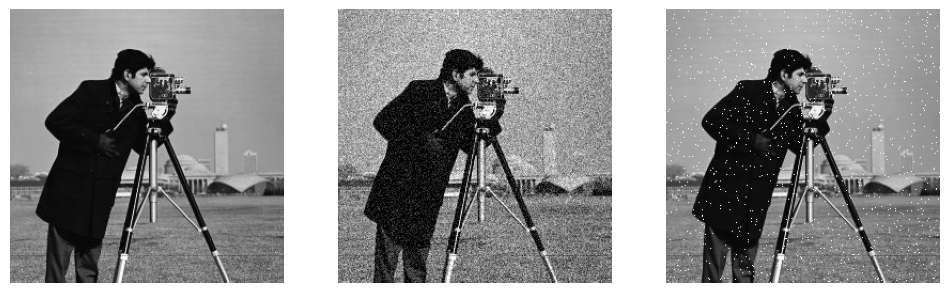

In [29]:
plt.figure(figsize=(12,5))

plt.subplot(1,3,1)
plt.imshow(img, cmap="gray")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(gaussian_noise, cmap="gray")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(sp_noice, cmap="gray")
plt.axis("off")

plt.show()

In [30]:
mean_kernel = np.ones((5, 5), dtype=np.float32) / 25

In [41]:
mean_filtered_manual = cv2.filter2D(gaussian_noise, -1, mean_kernel)

In [42]:
mean_filtered_cv2 = cv2.blur(gaussian_noise, (5, 5))

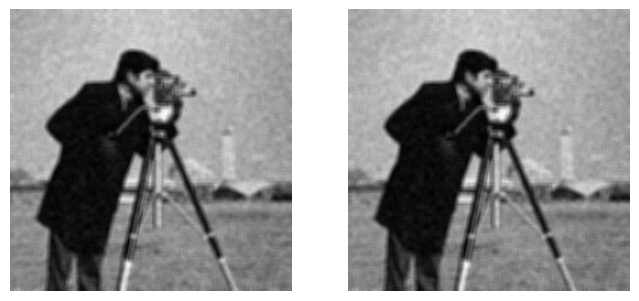

In [61]:
plt.figure(figsize=(8,5))

plt.subplot(1,2,1)
plt.imshow(mean_filtered_manual, cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(mean_filtered_cv2, cmap="gray")
plt.axis("off")

plt.show()

In [47]:
gaussian_1d = cv2.getGaussianKernel(5, sigma=1.5)
gaussian_2d_kernel = gaussian_1d @ gaussian_1d.T

In [49]:
gaussian_filtered_manual = cv2.filter2D(gaussian_noise, -1, gaussian_2d_kernel)

In [54]:
gaussian_filtered_cv2 = cv2.GaussianBlur(gaussian_noise, (5, 5), sigmaX=1.5)

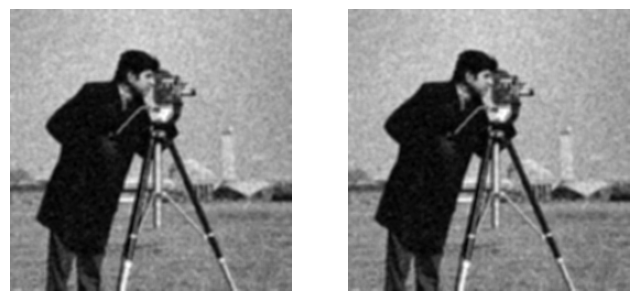

In [62]:
plt.figure(figsize=(8,5))

plt.subplot(1,2,1)
plt.imshow(gaussian_filtered_manual, cmap="gray")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(gaussian_filtered_cv2, cmap="gray")
plt.axis("off")

plt.show()

In [64]:
median_filtered_sp = cv2.medianBlur(sp_noice, 5)
mean_filtered_sp = cv2.blur(sp_noice, (5, 5))
gaussian_filtered_sp = cv2.GaussianBlur(sp_noice, (5, 5), sigmaX=1.5)

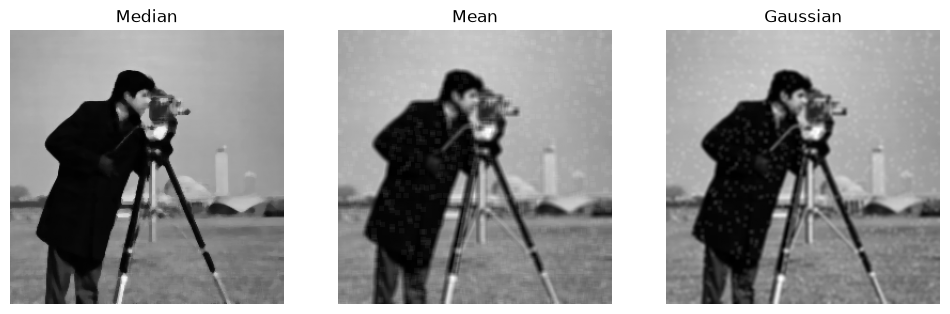

In [67]:
plt.figure(figsize=(12,5))

plt.subplot(1,3,1)
plt.imshow(median_filtered_sp, cmap="gray")
plt.title("Median")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mean_filtered_sp, cmap="gray")
plt.title("Mean")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(gaussian_filtered_sp, cmap="gray")
plt.title("Gaussian")
plt.axis("off")

plt.show()

In [ ]:
median_filtered_sp = cv2.medianBlur(sp_noice, 5)
